# Fakeddit Multimodal Misinformation Detection
### Stage 5 — Calibration Fix (Temperature Scaling) & Explainability (SHAP + Grad-CAM)

**This notebook has two parts:**

**Part A — Temperature Scaling.** Stage 4 found the fusion model is poorly calibrated (ECE 0.0525 overall, worst on the Misleading class at 0.0959) and that only 1% of its mistakes come with honest low confidence. This section fixes that with **temperature scaling** a standard, lightweight post-hoc calibration technique. It does **not** retrain or change the model's predictions at all, it only rescales the model's confidence scores to better match its actual accuracy, using one number ("temperature") fit on the validation set.

**Part B & C — Explainability.** Using the confidently-wrong examples saved in Stage 4, this section applies:
- **SHAP** on the text side, which words pushed the model toward its wrong prediction
- **Grad-CAM** on the image side, adapted for CLIP's Vision Transformer architecture, which regions of the image the model was "looking at"



## Step 0 — Setup

In [ ]:
!pip install -q transformers sentencepiece scikit-learn matplotlib pandas requests tqdm joblib pillow shap scipy


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import joblib
import requests
from PIL import Image
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings('ignore', category=UserWarning, module='PIL')

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DRIVE_ROOT = '/content/drive/MyDrive/fakeddit_calibration'
LABEL_COL = '3_way_label'
LABEL_NAMES = {0: 'Real', 1: 'Satire', 2: 'Misleading'}   # verified against Fakeddit's published convention in Stage 4
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")


Mounted at /content/drive
Using device: cpu


## Step 1 — Load the fusion model, shared split, and embeddings




In [ ]:
splits_dir = f'{DRIVE_ROOT}/metadata/splits_multimodal'
val_df  = pd.read_csv(f'{splits_dir}/val.csv')
test_df = pd.read_csv(f'{splits_dir}/test.csv')

clip_cache = np.load(f'{DRIVE_ROOT}/embeddings/clip_image_embeddings.npz', allow_pickle=True)
id_to_clip = dict(zip(clip_cache['ids'].tolist(), clip_cache['embeddings']))

text_val_emb  = np.load(f'{DRIVE_ROOT}/embeddings/roberta_multimodal_val.npy')
text_test_emb = np.load(f'{DRIVE_ROOT}/embeddings/roberta_multimodal_test.npy')
id_to_text_val  = dict(zip(val_df['id'], text_val_emb))
id_to_text_test = dict(zip(test_df['id'], text_test_emb))

def build_fusion(df, id_to_text):
    ids = df['id'].tolist()
    X_text = np.stack([id_to_text[i] for i in ids])
    X_image = np.stack([id_to_clip[i] for i in ids])
    X_fusion = np.concatenate([X_text, X_image], axis=1)
    y = df[LABEL_COL].values
    return X_fusion, y

X_fusion_val, y_val   = build_fusion(val_df, id_to_text_val)
X_fusion_test, y_test = build_fusion(test_df, id_to_text_test)

fusion_model = joblib.load(f'{DRIVE_ROOT}/models/fusion_shared_split.joblib')

val_proba_raw  = fusion_model.predict_proba(X_fusion_val)
test_proba_raw = fusion_model.predict_proba(X_fusion_test)
test_pred = np.argmax(test_proba_raw, axis=1)

print(f"Val: {len(y_val)}   Test: {len(y_test)}")
print(f"Test accuracy (unaffected by calibration): {(test_pred == y_test).mean():.4f}")


Val: 2986   Test: 2986
Test accuracy (unaffected by calibration): 0.8282


## Part A — Temperature Scaling

**In plain terms:** temperature scaling takes the model's existing predictions and "softens" or "sharpens" its confidence with a single number, `T`. If `T > 1`, all confidence scores get pulled closer together (less extreme), the right fix for an overconfident model like this one. If `T < 1`, confidences get pushed further apart. Critically, dividing by a positive constant before the softmax doesn't change *which* class gets the highest score, so **your model's predictions and accuracy stay exactly the same**, only the confidence numbers change, becoming more honest.

`T` is fit on the **validation set** (never the test set, to avoid leaking test information into the calibration) by finding the value that minimizes cross-entropy loss i.e. the value that makes the model's stated confidence match its actual correctness as closely as possible.


In [ ]:
def get_pseudo_logits(proba, eps=1e-12):
    """log(probability) is mathematically equivalent to the model's raw logits for temperature-scaling
    purposes: softmax(log(p)/T) == softmax(logits/T) for any T, since the missing normalization
    constant in log(p) cancels out inside the softmax. This lets us temperature-scale sklearn's
    predict_proba output directly, without needing access to pre-softmax logits."""
    return np.log(np.clip(proba, eps, 1.0))

def softmax_with_temperature(pseudo_logits, T):
    scaled = pseudo_logits / T
    scaled = scaled - scaled.max(axis=1, keepdims=True)
    exp_scaled = np.exp(scaled)
    return exp_scaled / exp_scaled.sum(axis=1, keepdims=True)

def nll_loss(T, pseudo_logits, y_true):
    if T <= 0:
        return np.inf
    proba = softmax_with_temperature(pseudo_logits, T)
    true_class_proba = proba[np.arange(len(y_true)), y_true]
    return -np.mean(np.log(np.clip(true_class_proba, 1e-12, 1.0)))


CALIBRATION_SUMMARY_PATH = f'{DRIVE_ROOT}/metadata/temperature_scaling_summary.json'

if os.path.exists(CALIBRATION_SUMMARY_PATH):
    print("Cached temperature-scaling results found — loading instead of refitting.\n")
    with open(CALIBRATION_SUMMARY_PATH) as f:
        calib_summary = json.load(f)
    best_T = calib_summary['temperature']
else:
    print("No cached results — fitting temperature on the validation set now.\n")
    val_pseudo_logits = get_pseudo_logits(val_proba_raw)
    result = minimize_scalar(nll_loss, bounds=(0.05, 10.0), method='bounded', args=(val_pseudo_logits, y_val))
    best_T = float(result.x)
    print(f"Fitted temperature: T = {best_T:.4f}  (T > 1 means the model was overconfident, as expected)")

print(f"\nUsing T = {best_T:.4f}")


No cached results — fitting temperature on the validation set now.

Fitted temperature: T = 1.4554  (T > 1 means the model was overconfident, as expected)

Using T = 1.4554


In [ ]:
def compute_ece(y_true_subset, proba_subset, n_bins=10):
    confidences_subset = np.max(proba_subset, axis=1)
    predictions_subset = np.argmax(proba_subset, axis=1)
    accuracies_subset = (predictions_subset == y_true_subset).astype(float)
    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    bin_stats = []
    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        in_bin = (confidences_subset > lo) & (confidences_subset <= hi)
        prop_in_bin = in_bin.mean()
        if prop_in_bin > 0:
            acc_in_bin = accuracies_subset[in_bin].mean()
            conf_in_bin = confidences_subset[in_bin].mean()
            ece += np.abs(acc_in_bin - conf_in_bin) * prop_in_bin
            bin_stats.append({'bin_range': [float(round(lo, 2)), float(round(hi, 2))],
                               'accuracy': float(acc_in_bin), 'confidence': float(conf_in_bin),
                               'proportion': float(prop_in_bin)})
    return float(ece), bin_stats


test_pseudo_logits = get_pseudo_logits(test_proba_raw)
test_proba_calibrated = softmax_with_temperature(test_pseudo_logits, best_T)

# Predictions are unchanged by design
assert np.array_equal(np.argmax(test_proba_raw, axis=1), np.argmax(test_proba_calibrated, axis=1)), \
    "Temperature scaling should never change predictions — something is wrong if this fails."

ece_before, bins_before = compute_ece(y_test, test_proba_raw, n_bins=10)
ece_after, bins_after = compute_ece(y_test, test_proba_calibrated, n_bins=10)

print(f"Overall ECE  before: {ece_before:.4f}")
print(f"Overall ECE  after:  {ece_after:.4f}")
print(f"Improvement: {ece_before - ece_after:.4f} ({(1 - ece_after/ece_before)*100:.1f}% reduction)")

per_class_before, per_class_after = {}, {}
for class_idx, class_name in LABEL_NAMES.items():
    mask = (y_test == class_idx)
    ece_b, _ = compute_ece(y_test[mask], test_proba_raw[mask], n_bins=10)
    ece_a, _ = compute_ece(y_test[mask], test_proba_calibrated[mask], n_bins=10)
    per_class_before[class_name] = round(ece_b, 4)
    per_class_after[class_name] = round(ece_a, 4)

print(f"\n{'Class':<12}{'ECE before':<14}{'ECE after':<12}")
for name in LABEL_NAMES.values():
    print(f"{name:<12}{per_class_before[name]:<14}{per_class_after[name]:<12}")


Overall ECE  before: 0.0525
Overall ECE  after:  0.0110
Improvement: 0.0415 (79.0% reduction)

Class       ECE before    ECE after   
Real        0.0269        0.0403      
Satire      0.0899        0.071       
Misleading  0.0959        0.0508      


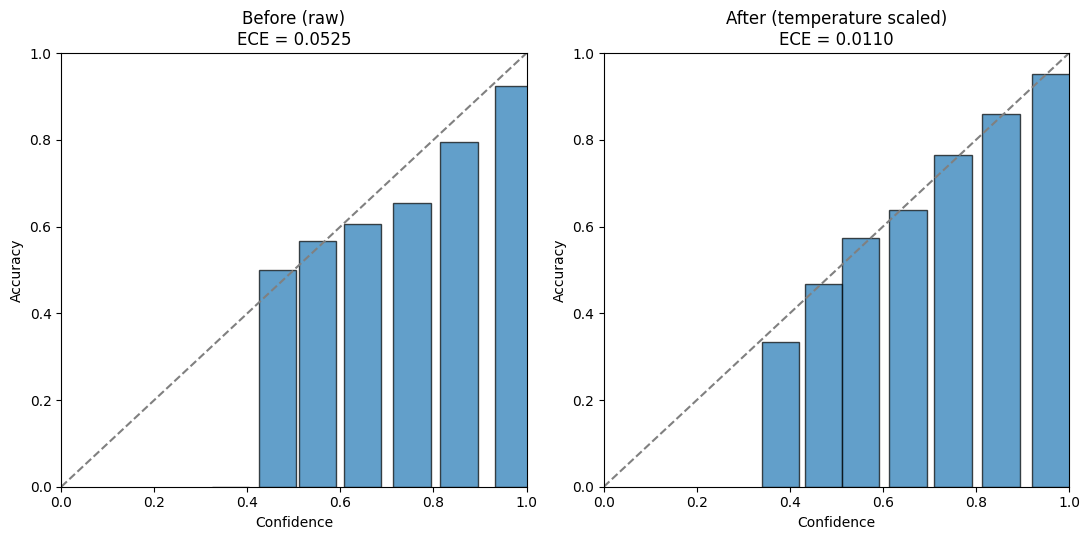

Saved -> /content/drive/MyDrive/fakeddit_calibration/metadata/temperature_scaling_summary.json


In [ ]:
# Reliability diagrams, before vs after
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, bins, title, ece in zip(axes, [bins_before, bins_after], ['Before (raw)', 'After (temperature scaled)'], [ece_before, ece_after]):
    conf = [b['confidence'] for b in bins]
    acc_ = [b['accuracy'] for b in bins]
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
    ax.bar(conf, acc_, width=0.08, alpha=0.7, edgecolor='black')
    ax.set_title(f"{title}\nECE = {ece:.4f}")
    ax.set_xlabel('Confidence')
    ax.set_ylabel('Accuracy')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(f'{DRIVE_ROOT}/figures/temperature_scaling_before_after.png', dpi=150)
plt.show()

if not os.path.exists(CALIBRATION_SUMMARY_PATH):
    calib_summary = {
        'temperature': round(best_T, 4),
        'overall_ece_before': round(ece_before, 4),
        'overall_ece_after': round(ece_after, 4),
        'per_class_ece_before': per_class_before,
        'per_class_ece_after': per_class_after,
        'note': 'Fitted on validation set; predictions unchanged (verified via assertion above).',
    }
    with open(CALIBRATION_SUMMARY_PATH, 'w') as f:
        json.dump(calib_summary, f, indent=2)
    np.save(f'{DRIVE_ROOT}/embeddings/fusion_test_calibrated_proba.npy', test_proba_calibrated)
    print(f"Saved -> {CALIBRATION_SUMMARY_PATH}")


---

## Part B — SHAP: which words drove the (wrong) prediction?

Applied to the confidently-wrong examples saved in Stage 4, these are the cases where explainability has the most to reveal, since they're where the model's behavior most needs scrutiny. This uses SHAP's black-box text explainer: it perturbs (masks) words in the caption and observes how the fusion model's prediction changes, holding that example's actual image embedding fixed. It doesn't require internal model access, so it works directly with the existing sklearn fusion model.


In [ ]:
from transformers import RobertaTokenizer, RobertaModel

tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
roberta = RobertaModel.from_pretrained('roberta-base').to(device).eval()

@torch.no_grad()
def extract_roberta_embeddings(texts, batch_size=32):
    embeddings = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        enc = tokenizer(list(batch), padding=True, truncation=True, max_length=128, return_tensors='pt').to(device)
        out = roberta(**enc)
        embeddings.append(out.last_hidden_state[:, 0, :].cpu().numpy())
    return np.concatenate(embeddings, axis=0)

confidently_wrong = pd.read_csv(f'{DRIVE_ROOT}/metadata/confidently_wrong_examples.csv')
shap_examples = confidently_wrong.head(3).reset_index(drop=True)
print(f"Explaining the {len(shap_examples)} most confidently-wrong examples:")
print(shap_examples[['clean_title', 'true_label_name', 'predicted_label_name', 'confidence']].to_string(index=False))


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Explaining the 3 most confidently-wrong examples:
                                                                                                                                                    clean_title true_label_name predicted_label_name  confidence
                                                                                                              the bottom of our loaf of bread was smiling at me            Real           Misleading    0.999536
                                                                                                                                             the sad tub is sad            Real           Misleading    0.999226
this isnt a poster but the rules allow for any this is a song called the sacred war sung by the red army in the defense of moscow in english subtitles included          Satire           Misleading    0.999198


In [ ]:
import shap

def make_predict_fn(fixed_image_embedding):
    def predict_fn(texts):
        text_embs = extract_roberta_embeddings(list(texts))
        img_embs = np.tile(fixed_image_embedding, (len(texts), 1))
        fusion_embs = np.concatenate([text_embs, img_embs], axis=1)
        return fusion_model.predict_proba(fusion_embs)
    return predict_fn

class_order = [LABEL_NAMES[i] for i in range(3)]
shap_results = []

for _, row in shap_examples.iterrows():
    img_emb = id_to_clip[row['id']]
    predict_fn = make_predict_fn(img_emb)
    masker = shap.maskers.Text()
    explainer = shap.Explainer(predict_fn, masker, output_names=class_order)
    sv = explainer([row['clean_title']])

    predicted_idx = int(row['predicted_label'])
    print(f"\n{'='*70}")
    print(f"\"{row['clean_title']}\"")
    print(f"True: {row['true_label_name']}  |  Predicted: {row['predicted_label_name']} (conf={row['confidence']:.3f})")
    shap.plots.text(sv[0, :, predicted_idx])
    shap_results.append({'id': row['id'], 'clean_title': row['clean_title'],
                          'true_label': row['true_label_name'], 'predicted_label': row['predicted_label_name']})


  0%|          | 0/110 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:11, 11.03s/it]               


"the bottom of our loaf of bread was smiling at me"
True: Real  |  Predicted: Misleading (conf=1.000)



"the sad tub is sad"
True: Real  |  Predicted: Misleading (conf=0.999)


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [01:04, 64.97s/it]               


"this isnt a poster but the rules allow for any this is a song called the sacred war sung by the red army in the defense of moscow in english subtitles included"
True: Satire  |  Predicted: Misleading (conf=0.999)


---

## Part C — Grad-CAM: which part of the image drove the (wrong) prediction?

**Technical note on how this works:** the fusion model's classifier head is a scikit-learn `MLPClassifier`, which being NumPy-based rather than PyTorch doesn't support the automatic differentiation Grad-CAM needs. To get real gradients flowing from the prediction back through CLIP's vision encoder, this section first **reconstructs the trained sklearn MLP as an equivalent PyTorch module**, copying over its exact learned weights, and verifies numerically that it reproduces sklearn's predictions before using it for anything. This gives an honest, gradient-based explanation rather than an approximation.


In [ ]:
def sklearn_mlp_to_torch(mlp):
    layers = []
    n_layers = len(mlp.coefs_)
    for i in range(n_layers):
        in_dim, out_dim = mlp.coefs_[i].shape
        linear = nn.Linear(in_dim, out_dim)
        linear.weight.data = torch.tensor(mlp.coefs_[i].T.copy(), dtype=torch.float32)
        linear.bias.data = torch.tensor(mlp.intercepts_[i].copy(), dtype=torch.float32)
        layers.append(linear)
        if i < n_layers - 1:
            layers.append(nn.ReLU())
    return nn.Sequential(*layers).to(device).eval()

torch_fusion_head = sklearn_mlp_to_torch(fusion_model)

# Verify the reconstruction is exact before trusting it for explanations
with torch.no_grad():
    sample = torch.tensor(X_fusion_test[:10], dtype=torch.float32).to(device)
    torch_proba = F.softmax(torch_fusion_head(sample), dim=1).cpu().numpy()
sklearn_proba_check = fusion_model.predict_proba(X_fusion_test[:10])
max_diff = np.abs(torch_proba - sklearn_proba_check).max()
print(f"Max difference between PyTorch reconstruction and original sklearn model: {max_diff:.2e}")
assert max_diff < 1e-4, "Reconstruction doesn't match the original model closely enough — do not trust Grad-CAM results."
print("Reconstruction verified — safe to use for gradient-based explanations.")


Max difference between PyTorch reconstruction and original sklearn model: 2.98e-07
Reconstruction verified — safe to use for gradient-based explanations.


In [ ]:
from transformers import CLIPProcessor, CLIPModel

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

gradcam_activations, gradcam_gradients = {}, {}

def forward_hook(module, inp, out):
    gradcam_activations['value'] = out[0] if isinstance(out, tuple) else out

def backward_hook(module, grad_in, grad_out):
    gradcam_gradients['value'] = grad_out[0] if isinstance(grad_out, tuple) else grad_out

target_layer = clip_model.vision_model.encoder.layers[-2]
target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(backward_hook)

def download_image_temp(url, save_path, timeout=8):
    try:
        r = requests.get(url, timeout=timeout, stream=True)
        if r.status_code != 200:
            return False
        with open(save_path, 'wb') as f:
            for block in r.iter_content(1024):
                f.write(block)
        with Image.open(save_path) as img:
            img.verify()
        return True
    except Exception:
        if os.path.exists(save_path):
            os.remove(save_path)
        return False

def compute_gradcam(image, text_embedding, target_class_idx):
    inputs = clip_processor(images=image, return_tensors='pt').to(device)
    output = clip_model.get_image_features(**inputs)   # triggers the hooks above

    # Same output-type handling needed here as in Stage 2
    if hasattr(output, 'image_embeds'):
        image_features = output.image_embeds
    elif hasattr(output, 'pooler_output'):
        image_features = output.pooler_output
    elif torch.is_tensor(output):
        image_features = output
    else:
        raise TypeError(f"Unexpected output type from get_image_features: {type(output)}")

    text_feat = torch.tensor(text_embedding, dtype=torch.float32).unsqueeze(0).to(device)
    fusion_input = torch.cat([text_feat, image_features], dim=1)

    logits = torch_fusion_head(fusion_input)
    target_score = logits[0, target_class_idx]

    clip_model.zero_grad()
    target_score.backward()

    activations = gradcam_activations['value'][0, 1:, :]
    gradients = gradcam_gradients['value'][0, 1:, :]
    weights = gradients.mean(dim=0)
    cam = F.relu((activations * weights).sum(dim=-1))

    grid_size = int(np.sqrt(cam.shape[0]))
    cam = cam.reshape(grid_size, grid_size).detach().cpu().numpy()
    cam = cam / (cam.max() + 1e-8)
    return cam


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

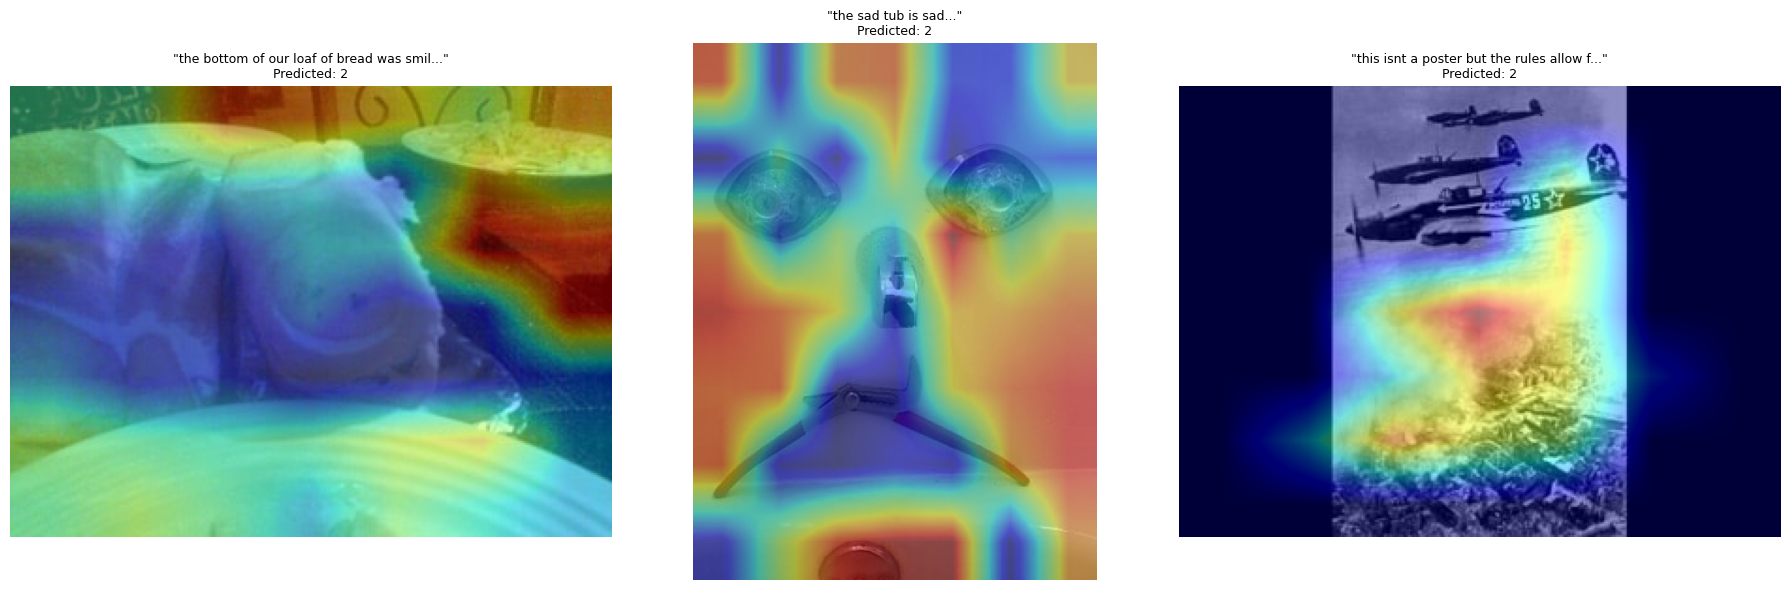

In [ ]:
GRADCAM_TMP_DIR = '/content/gradcam_images_tmp'
os.makedirs(GRADCAM_TMP_DIR, exist_ok=True)

# Need image_url and the exact RoBERTa embedding used for these examples, pull from the test split
gradcam_examples = shap_examples.merge(test_df[['id', 'image_url']], on='id', how='left')

fig, axes = plt.subplots(1, len(gradcam_examples), figsize=(6 * len(gradcam_examples), 6))
if len(gradcam_examples) == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, gradcam_examples.iterrows()):
    local_path = f"{GRADCAM_TMP_DIR}/{row['id']}.jpg"
    if not download_image_temp(row['image_url'], local_path):
        ax.set_title(f"Image unavailable for {row['id']}")
        ax.axis('off')
        continue

    image = Image.open(local_path).convert('RGB')
    text_emb = id_to_text_test[row['id']]
    predicted_idx = int(confidently_wrong[confidently_wrong['id'] == row['id']]['predicted_label'].iloc[0])

    cam = compute_gradcam(image, text_emb, predicted_idx)
    cam_resized = np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize(image.size, Image.BILINEAR))

    ax.imshow(image)
    ax.imshow(cam_resized, cmap='jet', alpha=0.45)
    ax.set_title(f"\"{row['clean_title'][:40]}...\"\nPredicted: {row['predicted_label']}", fontsize=9)
    ax.axis('off')

    os.remove(local_path)   # delete immediately after use, same never keep raw images, convention as Stage 2

plt.tight_layout()
plt.savefig(f'{DRIVE_ROOT}/figures/gradcam_confidently_wrong_examples.png', dpi=150)
plt.show()
